In [1]:

from pathlib import Path

cwd = Path.cwd()
PROJECT_ROOT = cwd.parent if cwd.name.lower() == "notebooks" else cwd

RESULTS_DIR = PROJECT_ROOT / "results"

required_files = [
    "baseline_metrics.csv",
    "day10_level1_logistic_regression.csv",
    "day11_level1_random_forest.csv"
]

for filename in required_files:
    path = RESULTS_DIR / filename
    print(f"{filename}: {'FOUND' if path.exists() else 'NOT FOUND'}")


baseline_metrics.csv: FOUND
day10_level1_logistic_regression.csv: FOUND
day11_level1_random_forest.csv: FOUND


In [2]:
# Load and compare the metrics


import pandas as pd

baseline = pd.read_csv(RESULTS_DIR / "baseline_metrics.csv")
lr_level1 = pd.read_csv(
    RESULTS_DIR / "day10_level1_logistic_regression.csv"
)
rf_level1 = pd.read_csv(
    RESULTS_DIR / "day11_level1_random_forest.csv"
)

print("Baseline columns:", baseline.columns.tolist())
print("\nBaseline results:")
display(baseline)

print("\nLevel 1 Logistic Regression:")
display(lr_level1)

print("\nLevel 1 Random Forest:")
display(rf_level1)


Baseline columns: ['model', 'accuracy', 'precision', 'recall', 'f1_score']

Baseline results:


,model,accuracy,precision,recall,f1_score
0,Logistic Regression,0.855059,0.74037,0.612883,0.670621
1,Random Forest,0.860740,0.77068,0.600128,0.674794



Level 1 Logistic Regression:


,experiment,day,model,accuracy,precision,recall,f1_score
0,Level 1,10,Logistic Regression,0.85552,0.730345,0.633929,0.67873



Level 1 Random Forest:


,experiment,day,model,accuracy,precision,recall,f1_score
0,Level 1,11,Random Forest,0.861508,0.760972,0.61926,0.682841


In [4]:
# Compare the metrics


metrics = ["accuracy", "precision", "recall", "f1_score"]

# Normalize model names for matching
baseline = baseline.copy()
baseline["model"] = baseline["model"].astype(str).str.strip()
lr_level1 = lr_level1.copy()
rf_level1 = rf_level1.copy()

baseline_models = {
    "Logistic Regression": baseline[
        baseline["model"].str.lower().eq("logistic regression")
    ],
    "Random Forest": baseline[
        baseline["model"].str.lower().eq("random forest")
    ],
}

level1_models = {
    "Logistic Regression": lr_level1,
    "Random Forest": rf_level1,
}

comparison_rows = []

for model_name in baseline_models:
    base_row = baseline_models[model_name]
    level1_row = level1_models[model_name]

    if base_row.empty:
        print(f"Baseline result not found for: {model_name}")
        continue

    row = {
        "model": model_name,
        "experiment": "Baseline vs Level 1"
    }

    for metric in metrics:
        baseline_value = float(base_row.iloc[0][metric])
        level1_value = float(level1_row.iloc[0][metric])

        row[f"baseline_{metric}"] = baseline_value
        row[f"level1_{metric}"] = level1_value
        row[f"change_{metric}"] = level1_value - baseline_value

    comparison_rows.append(row)

comparison_df = pd.DataFrame(comparison_rows)
display(comparison_df.round(4))


,model,experiment,baseline_accuracy,level1_accuracy,change_accuracy,baseline_precision,level1_precision,change_precision,baseline_recall,level1_recall,change_recall,baseline_f1_score,level1_f1_score,change_f1_score
0,Logistic Regression,Baseline vs Level 1,0.8551,0.8555,0.0005,0.7404,0.7303,-0.0100,0.6129,0.6339,0.0210,0.6706,0.6787,0.0081
1,Random Forest,Baseline vs Level 1,0.8607,0.8615,0.0008,0.7707,0.7610,-0.0097,0.6001,0.6193,0.0191,0.6748,0.6828,0.0080


In [5]:
# Save the comparison


comparison_path = RESULTS_DIR / "baseline_vs_level1_comparison.csv"
comparison_df.to_csv(comparison_path, index=False)

print("Comparison saved to:", comparison_path)


Comparison saved to: d:\VS Code\Projects\python\Internship\results\baseline_vs_level1_comparison.csv


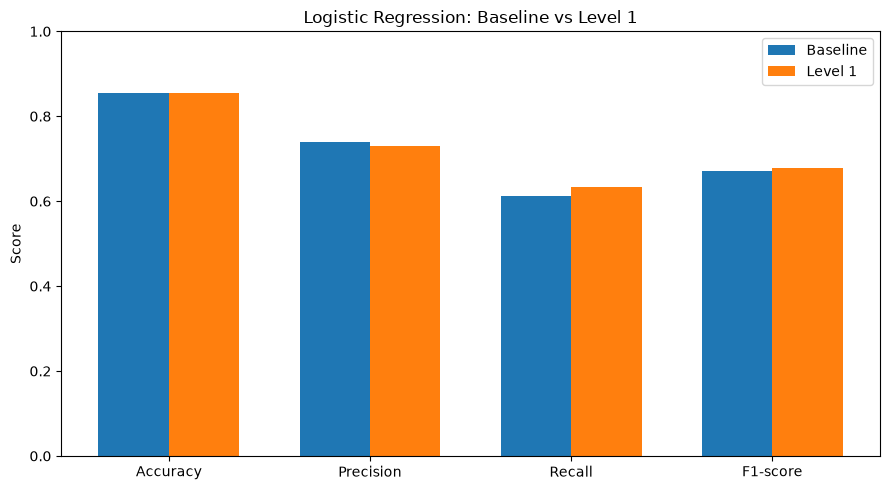

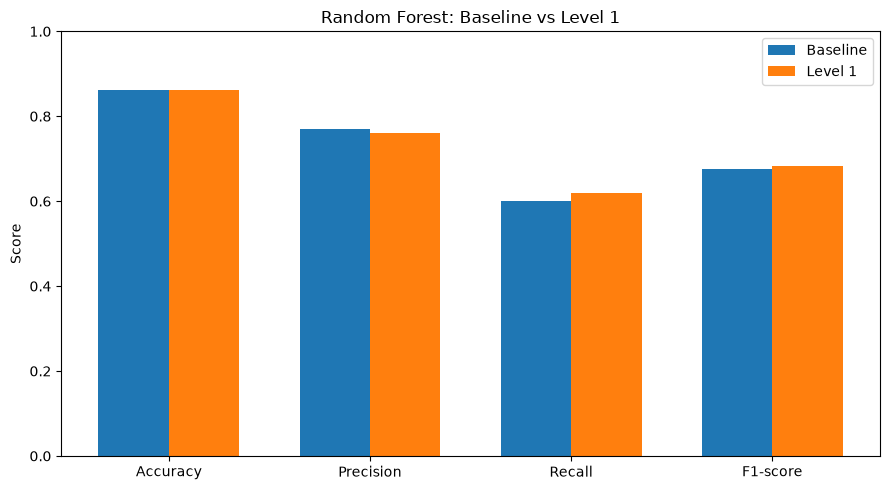

In [6]:
# comparison chart


import matplotlib.pyplot as plt
import numpy as np

metrics = ["accuracy", "precision", "recall", "f1_score"]
labels = ["Accuracy", "Precision", "Recall", "F1-score"]

for model_name in comparison_df["model"].unique():
    row = comparison_df.loc[
        comparison_df["model"] == model_name
    ].iloc[0]

    baseline_values = [
        row[f"baseline_{metric}"] for metric in metrics
    ]
    level1_values = [
        row[f"level1_{metric}"] for metric in metrics
    ]

    x = np.arange(len(labels))
    width = 0.35

    fig, ax = plt.subplots(figsize=(9, 5))
    ax.bar(x - width / 2, baseline_values, width, label="Baseline")
    ax.bar(x + width / 2, level1_values, width, label="Level 1")

    ax.set_title(f"{model_name}: Baseline vs Level 1")
    ax.set_ylabel("Score")
    ax.set_xticks(x)
    ax.set_xticklabels(labels)
    ax.set_ylim(0, 1)
    ax.legend()
    fig.tight_layout()

    safe_name = model_name.lower().replace(" ", "_")
    fig.savefig(
        PROJECT_ROOT / "figures" / f"{safe_name}_baseline_vs_level1.png",
        dpi=150,
        bbox_inches="tight"
    )
    plt.show()
    plt.close(fig)
